In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Connect and Access Git Repository

import os
import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 318, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 318 (delta 29), reused 16 (delta 7), pack-reused 264 (from 1)
Receiving objects: 100% (318/318), 19.06 MiB | 18.39 MiB/s, done.
Resolving deltas: 100% (146/146), done.
/content/bachelor-thesis
Repo exists: True


In [4]:
!git pull

Already up to date.


In [5]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.dataset import PTBXLAnoFormerDataset
from explainability.attention import AnoFormerExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [15]:
DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "anoformer_80epochs.pt"

print("MODEL_DIR:", MODEL_DIR)
print("MODEL_PATH:", MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer_80epochs.pt


In [16]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [17]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [18]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [19]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [20]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [21]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=32,
    NumHeads=4,
    NumEncoderLayers=1,
    NumDecoderLayers=1,
    DiscriminatorLayers=1,
    ForwardDimension=64,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [22]:
batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [ ]:
# Instead of retraining, I can just reload the saved model and use directly for anomaly detection and evaluation etc... no need to run the Training cell

#MODEL_PATH = MODEL_DIR / "anoformer_20epochs.pt"
#MODEL_PATH = MODEL_DIR / "anoformer_40epochs.pt"
MODEL_PATH = MODEL_DIR / "anoformer_80epochs.pt"

AnoFormer.Load(str(MODEL_PATH))

In [24]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=80,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/80 | G-Total=8.3647 | G-GAN=1.4188 | G-Rec=0.6946 | D=0.4793
Epoche    2/80 | G-Total=11.2268 | G-GAN=1.5818 | G-Rec=0.9645 | D=0.3950
Epoche    3/80 | G-Total=5.2483 | G-GAN=0.8424 | G-Rec=0.4406 | D=0.6644
Epoche    4/80 | G-Total=11.5369 | G-GAN=1.8155 | G-Rec=0.9721 | D=0.3479
Epoche    5/80 | G-Total=4.9171 | G-GAN=0.8285 | G-Rec=0.4089 | D=0.6772
Epoche    6/80 | G-Total=11.6909 | G-GAN=1.8942 | G-Rec=0.9797 | D=0.3618
Epoche    7/80 | G-Total=4.7762 | G-GAN=0.8340 | G-Rec=0.3942 | D=0.6816
Epoche    8/80 | G-Total=11.6229 | G-GAN=1.7417 | G-Rec=0.9881 | D=0.3993
Epoche    9/80 | G-Total=4.5507 | G-GAN=0.8084 | G-Rec=0.3742 | D=0.6721
Epoche   10/80 | G-Total=11.4539 | G-GAN=1.6431 | G-Rec=0.9811 | D=0.4127
Epoche   11/80 | G-Total=4.4568 | G-GAN=0.7926 | G-Rec=0.3664 | D=0.6881
Epoche   12/80 | G-Total=11.3819 | G-GAN=1.6222 | G-Rec=0.9760 | D=0.4180
Epoche   13/80 | G-Total=4.4093 | G-GAN=0.7909 | G-Rec=0.3

In [25]:
# Anomaly Detection

print("\n── AnoFormer Anomaly Detection ───────────────────────────")

AnomalyScores, BinaryPredictions = AnoFormer.DetectAnomalies(test_loader)

print("Scores shape:", AnomalyScores.shape)
print("Predictions shape:", BinaryPredictions.shape)
print("Detected anomalous ECG records:", BinaryPredictions.sum())
print("Threshold:", AnoFormer.AnomalyLimit)


── AnoFormer Anomaly Detection ───────────────────────────
Scores shape: (2198,)
Predictions shape: (2198,)
Detected anomalous ECG records: 110
Threshold: 0.8825104236602783


In [26]:
correct_normal = np.where(
    (y_test == 0) &
    (BinaryPredictions == 0)
)[0]

NormalIndex = correct_normal[
    np.argmin(AnomalyScores[correct_normal])

]

correct_anomaly = np.where(
    (y_test == 1) &
    (BinaryPredictions == 1)
)[0]

AnomalousIndex = correct_anomaly[
    np.argmax(AnomalyScores[correct_anomaly])
]

In [27]:
# Evaluation

from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score

print(confusion_matrix(y_test, BinaryPredictions))
print(classification_report(y_test, BinaryPredictions))

print("ROC-AUC:", roc_auc_score(y_test, AnomalyScores))
print("PR-AUC:", average_precision_score(y_test, AnomalyScores))

[[ 945   18]
 [1143   92]]
              precision    recall  f1-score   support

           0       0.45      0.98      0.62       963
           1       0.84      0.07      0.14      1235

    accuracy                           0.47      2198
   macro avg       0.64      0.53      0.38      2198
weighted avg       0.67      0.47      0.35      2198

ROC-AUC: 0.6231631078655181
PR-AUC: 0.7040469086993824


In [28]:
# Evaluation

print("\n── AnoFormer Evaluation ───────────────────────")

Metrics = AnoFormer.Evaluate(test_loader, y_test)
print(Metrics)


── AnoFormer Evaluation ───────────────────────
  Precision           : 0.8667
  Recall              : 0.0842
  F1Score             : 0.1535
  Threshold           : 0.88251
  TruePositive        : 104
  FalsePositive       : 16
  FalseNegative       : 1131
{'Precision': 0.8667, 'Recall': 0.0842, 'F1Score': 0.1535, 'Threshold': 0.88251, 'TruePositive': 104, 'FalsePositive': 16, 'FalseNegative': 1131}


In [29]:
# Save the Model

print("\n── Saving AnoFormer ──────────────────────────────────────")

AnoFormer.Save(str(MODEL_PATH))


── Saving AnoFormer ──────────────────────────────────────
Modell gespeichert unter: /content/drive/MyDrive/ECG data/results/models/anoformer_80epochs.pt


In [30]:
# Correctly predicted normal samples
correct_normal_indices = np.where(
    (y_test == 0) & (BinaryPredictions == 0)
)[0]

# Correctly predicted anomalous samples
correct_anomaly_indices = np.where(
    (y_test == 1) & (BinaryPredictions == 1)
)[0]

# Pick the most confident normal: lowest anomaly score
NormalIndex = correct_normal_indices[
    np.argmin(AnomalyScores[correct_normal_indices])
]

# Pick the most confident anomaly: highest anomaly score
AnomalousIndex = correct_anomaly_indices[
    np.argmax(AnomalyScores[correct_anomaly_indices])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", AnomalyScores[NormalIndex])
print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", AnomalyScores[AnomalousIndex])

Selected normal index: 1595
Normal score: 0.06055226
Selected anomalous index: 1861
Anomalous score: 7.9878945


Normal index: 1595 Label: 0
Anomalous index: 1861 Label: 1


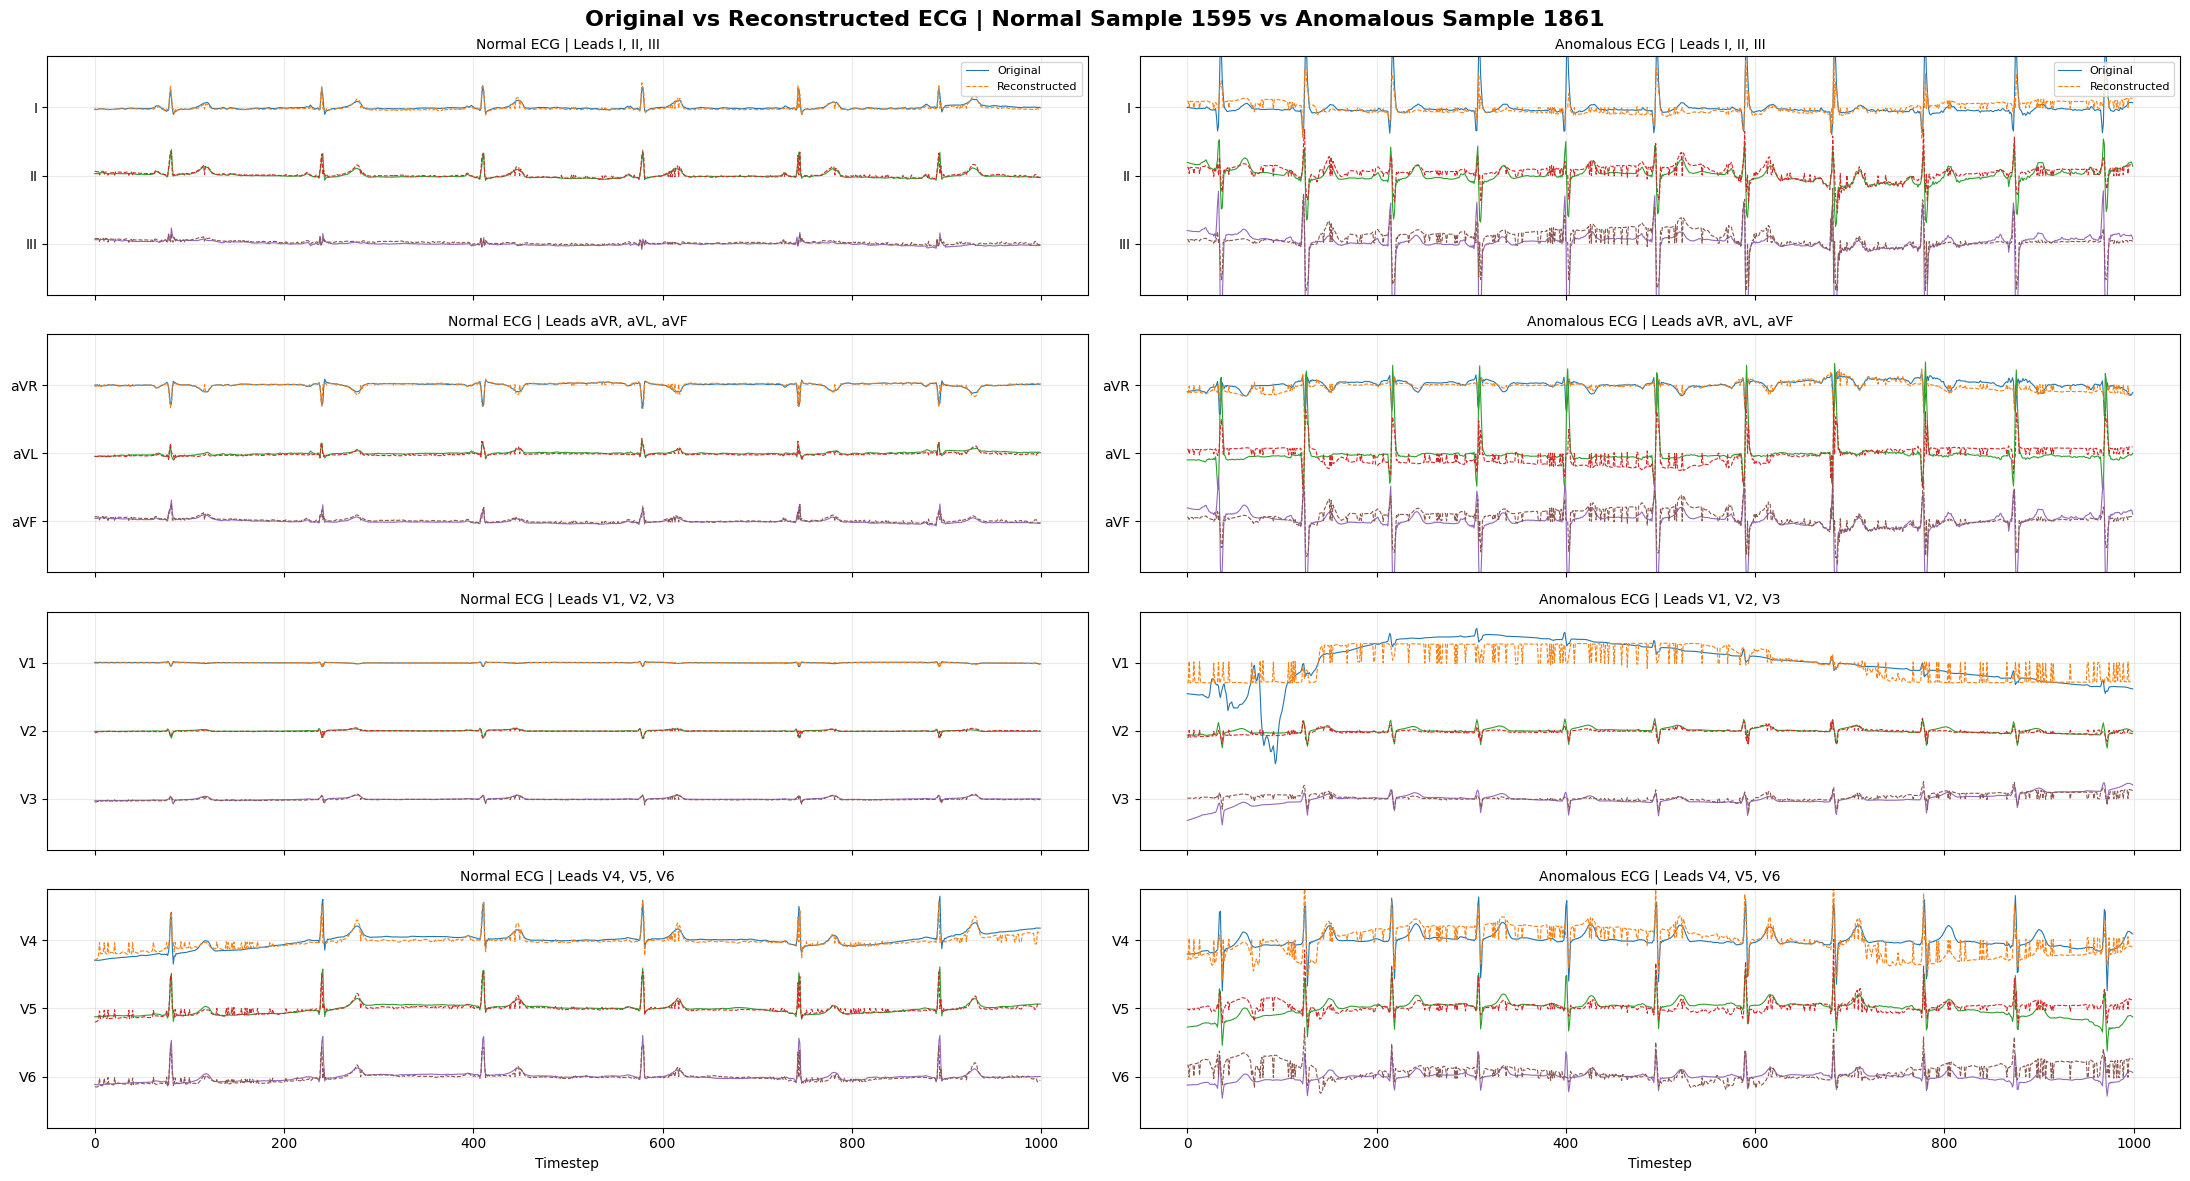

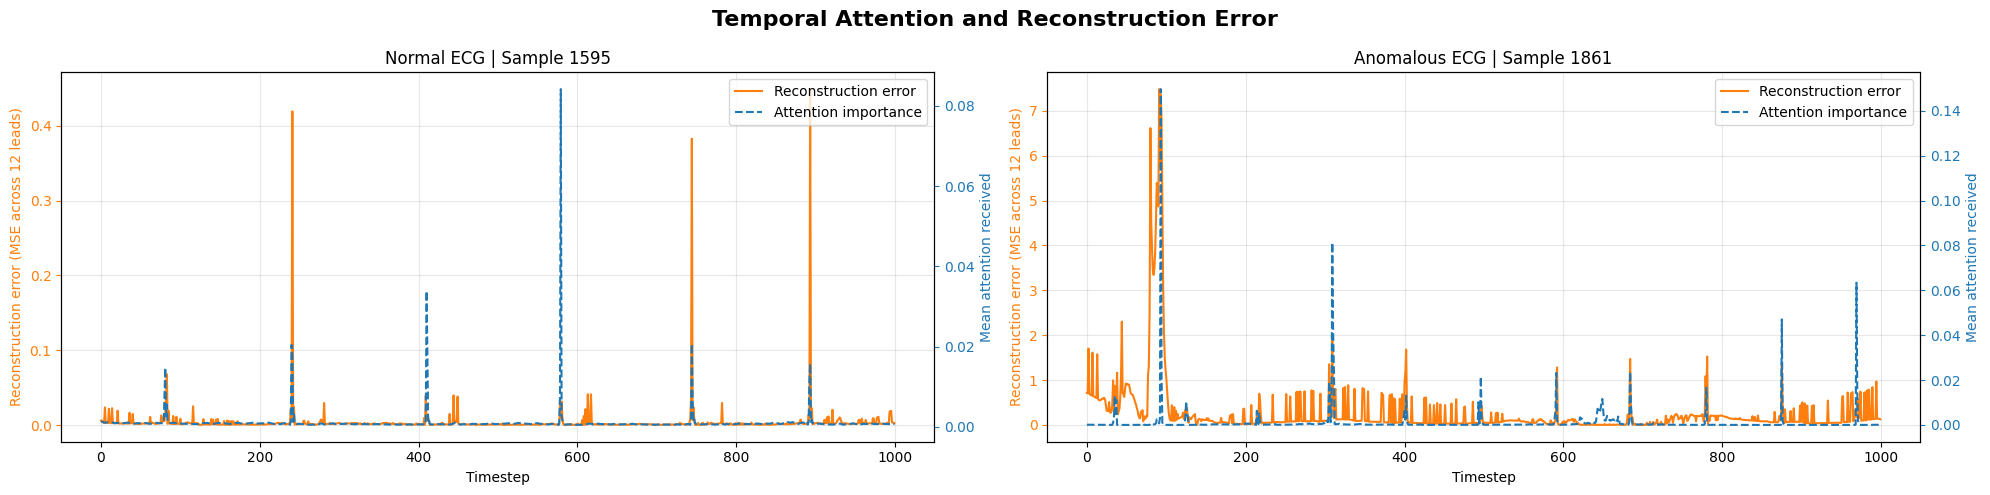

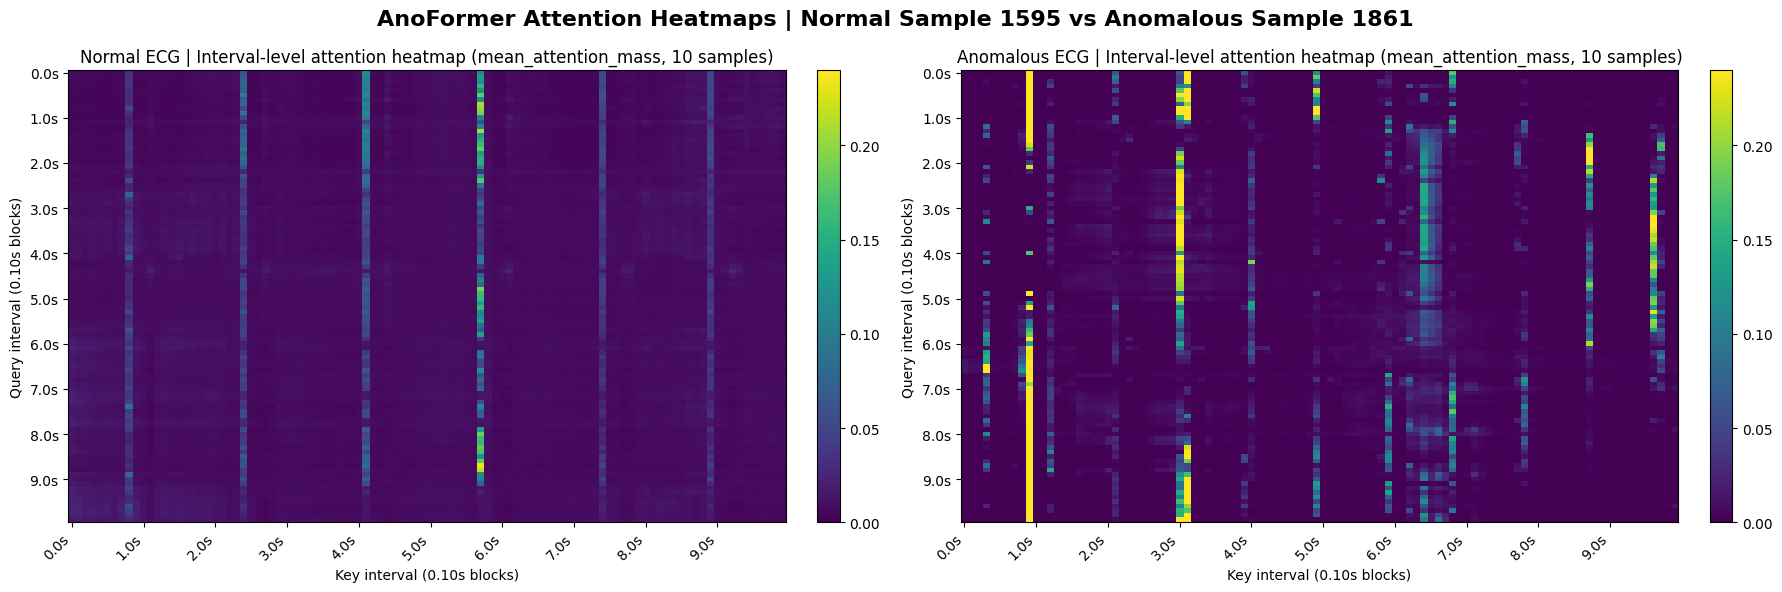

In [31]:
# Attention-based Explainability: Normal vs Anomalous

import numpy as np

Explainer = AnoFormerExplainability(AnoFormer)


NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(AnoFormer.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(AnoFormer.Device)

print("Normal index:", NormalIndex, "Label:", NormalLabel.item())
print("Anomalous index:", AnomalousIndex, "Label:", AnomalousLabel.item())

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    BlockIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

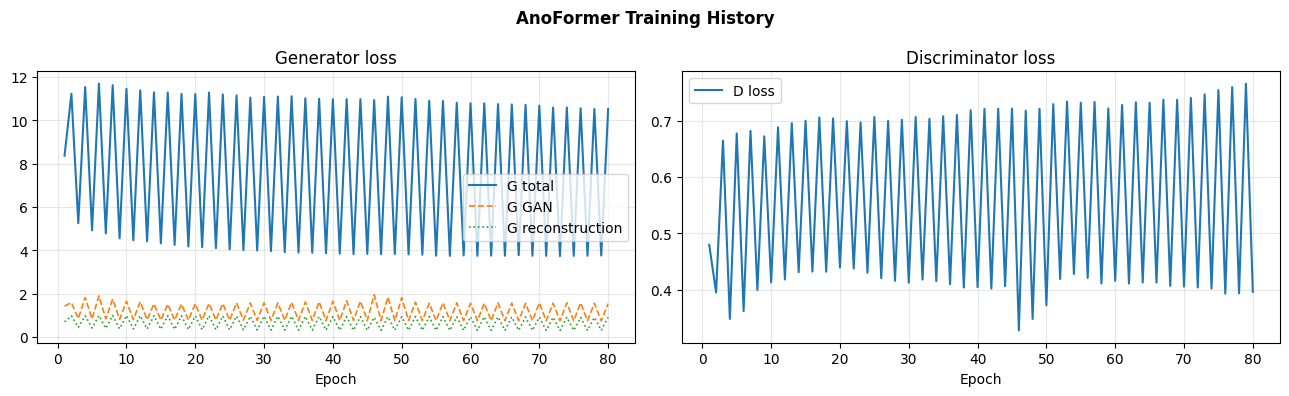

In [32]:
# Show training loss

Explainer.ShowTrainingHistory()